# 05 回测与绩效归因

## 目标
- 向量化回测：根据持仓矩阵计算组合收益
- 交易成本建模：A股单边0.1%（印花税+佣金）
- 绩效指标：年化收益、波动率、夏普比率、最大回撤、超额收益
- 与基准对比：等权持有全部成分股
- 可视化：收益曲线、回撤图、月度热力图

## 基准
等权持有全部沪深300精选成分股（Buy & Hold Equal Weight）

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

print('✓ 依赖加载完毕')

✓ 依赖加载完毕


## 2. 加载数据

In [2]:
ret_df = pd.read_csv('data/ret_df.csv', index_col=0, parse_dates=True)
close_df = pd.read_csv('data/close_df.csv', index_col=0, parse_dates=True)

try:
    portfolio_weights = pd.read_csv('data/portfolio_weights.csv', index_col=0, parse_dates=True)
    print(f'✓ 加载持仓权重: {portfolio_weights.shape}')
except FileNotFoundError:
    print('⚠ portfolio_weights.csv 未找到，请先运行 04_model.ipynb')
    print('  使用模拟持仓继续演示...')
    # 模拟持仓：每月持有全部股票的等权组合
    portfolio_weights = pd.DataFrame(1.0/len(ret_df.columns), index=ret_df.index, columns=ret_df.columns)

print(f'收益率矩阵: {ret_df.shape}')
print(f'日期范围: {ret_df.index[0].strftime("%Y-%m-%d")} ~ {ret_df.index[-1].strftime("%Y-%m-%d")}')
print(f'股票数: {len(ret_df.columns)}')

✓ 加载持仓权重: (717, 40)
收益率矩阵: (716, 40)
日期范围: 2023-01-04 ~ 2025-12-31
股票数: 40


## 3. 回测计算

### 3.1 策略组合收益

In [3]:
TRADING_COST = 0.001  # 单边0.1%

# 对齐持仓和收益
common_dates = portfolio_weights.index.intersection(ret_df.index)
common_stocks = portfolio_weights.columns.intersection(ret_df.columns)

pw = portfolio_weights.loc[common_dates, common_stocks]
rr = ret_df.loc[common_dates, common_stocks]

print(f'对齐后: {pw.shape} (日期x股票)')

# 逐日计算组合收益
portfolio_ret = (pw * rr).sum(axis=1)

# 计算换手率并扣除交易成本
turnover = pw.diff().abs().sum(axis=1) / 2  # 单边换手
cost = turnover * TRADING_COST
portfolio_ret_net = portfolio_ret - cost.shift(1).fillna(0)

print(f'策略日收益 (费后)')
portfolio_ret_net.describe().round(6)

对齐后: (716, 40) (日期x股票)
策略日收益 (费后)


count    716.000000
mean       0.000900
std        0.013220
min       -0.086841
25%       -0.006398
50%        0.000040
75%        0.006657
max        0.101913
dtype: float64

In [4]:
# ===== 基准组合：等权持有全部股票 =====
n_stocks = len(common_stocks)
benchmark_weights = pd.DataFrame(1.0 / n_stocks, index=rr.index, columns=common_stocks)
benchmark_ret = (benchmark_weights * rr).sum(axis=1)

print(f'基准日收益 (等权)')
benchmark_ret.describe().round(6)

基准日收益 (等权)


count    716.000000
mean       0.000337
std        0.011165
min       -0.078979
25%       -0.005176
50%       -0.000293
75%        0.005352
max        0.083086
dtype: float64

## 4. 绩效指标

In [5]:
def compute_performance_metrics(daily_returns, risk_free_rate=0.0, label='Strategy'):
    """
    计算全面的绩效指标
    """
    rets = daily_returns.dropna()
    n_days = len(rets)
    n_years = n_days / 252
    
    if n_days == 0:
        return {}
    
    # 累计收益
    cumulative = (1 + rets).cumprod()
    total_return = cumulative.iloc[-1] - 1
    
    # 年化收益
    annual_return = (1 + total_return) ** (1 / n_years) - 1
    
    # 年化波动率
    annual_vol = rets.std() * np.sqrt(252)
    
    # 夏普比率
    sharpe = (annual_return - risk_free_rate) / (annual_vol + 1e-10)
    
    # 最大回撤
    cum_max = cumulative.expanding().max()
    drawdown = cumulative / cum_max - 1
    max_drawdown = drawdown.min()
    
    # 最大回撤持续期
    dd_start = None
    dd_end = None
    max_dd_duration = 0
    current_dd_start = None
    for i, dd in enumerate(drawdown.values):
        if dd < -0.001 and current_dd_start is None:
            current_dd_start = drawdown.index[i]
        elif dd >= -0.001 and current_dd_start is not None:
            duration = (drawdown.index[i] - current_dd_start).days
            if duration > max_dd_duration:
                max_dd_duration = duration
                dd_start = current_dd_start
                dd_end = drawdown.index[i]
            current_dd_start = None
    
    # 正收益日比例
    win_rate = (rets > 0).mean()
    
    # 盈亏比
    avg_win = rets[rets > 0].mean() if (rets > 0).any() else 0
    avg_loss = abs(rets[rets < 0].mean()) if (rets < 0).any() else 1
    profit_loss_ratio = avg_win / (avg_loss + 1e-10)
    
    # Calmar比率
    calmar = annual_return / (abs(max_drawdown) + 1e-10)
    
    # Sortino比率（下行波动）
    downside_rets = rets[rets < 0]
    downside_vol = downside_rets.std() * np.sqrt(252) if len(downside_rets) > 0 else 0
    sortino = (annual_return - risk_free_rate) / (downside_vol + 1e-10)
    
    return {
        'label': label,
        '累计收益': f'{total_return:.2%}',
        '年化收益率': f'{annual_return:.2%}',
        '年化波动率': f'{annual_vol:.2%}',
        '夏普比率': f'{sharpe:.3f}',
        'Sortino比率': f'{sortino:.3f}',
        'Calmar比率': f'{calmar:.3f}',
        '最大回撤': f'{max_drawdown:.2%}',
        '最大回撤天数': max_dd_duration,
        '胜率': f'{win_rate:.2%}',
        '盈亏比': f'{profit_loss_ratio:.2f}',
        '日均收益(bp)': f'{rets.mean()*10000:.2f}',
    }


# 计算策略和基准绩效
metrics_strategy = compute_performance_metrics(portfolio_ret_net, label='Multi-Factor Strategy')
metrics_benchmark = compute_performance_metrics(benchmark_ret, label='Equal-Weight Benchmark')

# 超额收益
excess_ret = portfolio_ret_net - benchmark_ret
metrics_excess = compute_performance_metrics(excess_ret, label='Excess Return')

In [6]:
# ===== 绩效报告 =====
print('=' * 80)
print('                      回测绩效报告')
print('=' * 80)
print(f'{"指标":<20s} {"策略":>15s} {"基准":>15s} {"超额":>15s}')
print('-' * 80)

metrics_keys = ['年化收益率', '年化波动率', '夏普比率', 'Sortino比率', 'Calmar比率',
                '最大回撤', '胜率', '盈亏比', '日均收益(bp)']

for key in metrics_keys:
    s = metrics_strategy.get(key, 'N/A')
    b = metrics_benchmark.get(key, 'N/A')
    e = metrics_excess.get(key, 'N/A')
    print(f'{key:<20s} {s:>15s} {b:>15s} {e:>15s}')

print('=' * 80)
print(f'最大回撤持续天数: {metrics_strategy.get("最大回撤天数", "N/A")} 天')

                      回测绩效报告
指标                                策略              基准              超额
--------------------------------------------------------------------------------
年化收益率                         22.73%           7.17%          14.50%
年化波动率                         20.99%          17.72%          11.40%
夏普比率                           1.083           0.405           1.271
Sortino比率                      1.701           0.605           2.327
Calmar比率                       1.181           0.395           1.919
最大回撤                         -19.24%         -18.13%          -7.55%
胜率                            50.42%          47.63%          50.98%
盈亏比                             1.20            1.20            1.20
日均收益(bp)                        9.00            3.37            5.63
最大回撤持续天数: 351 天


## 5. 可视化

### 5.1 累计收益曲线

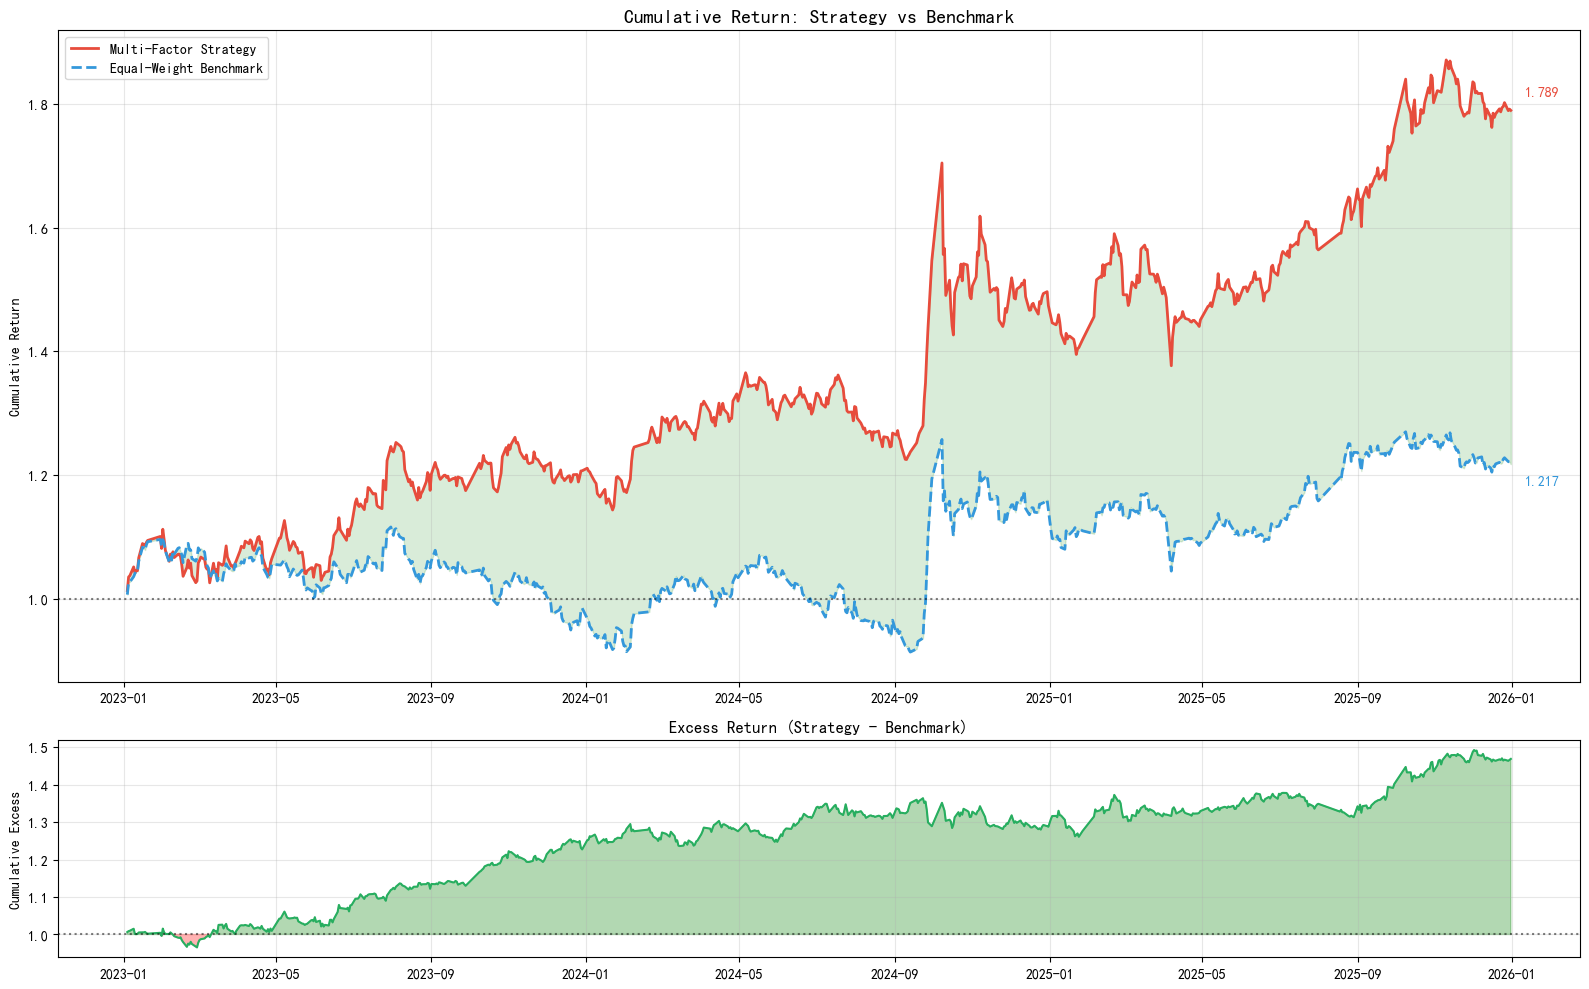

In [7]:
strategy_cum = (1 + portfolio_ret_net).cumprod()
benchmark_cum = (1 + benchmark_ret).cumprod()
excess_cum = (1 + excess_ret).cumprod()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 10), gridspec_kw={'height_ratios': [3, 1]})

# 主图: 策略 vs 基准
ax1.plot(strategy_cum.index, strategy_cum.values, '#e74c3c', linewidth=2, label=f'Multi-Factor Strategy')
ax1.plot(benchmark_cum.index, benchmark_cum.values, '#3498db', linewidth=2, linestyle='--', label=f'Equal-Weight Benchmark')
ax1.fill_between(strategy_cum.index, strategy_cum.values, benchmark_cum.values,
                 alpha=0.15, color='green' if strategy_cum.iloc[-1] > benchmark_cum.iloc[-1] else 'red')
ax1.axhline(y=1.0, color='black', linestyle=':', alpha=0.5)
ax1.set_title('Cumulative Return: Strategy vs Benchmark', fontsize=14, fontweight='bold')
ax1.set_ylabel('Cumulative Return')
ax1.legend(loc='upper left')
ax1.grid(True, alpha=0.3)

# 标注终值
final_s = strategy_cum.iloc[-1]
final_b = benchmark_cum.iloc[-1]
ax1.annotate(f'{final_s:.3f}', xy=(strategy_cum.index[-1], final_s),
            xytext=(10, 10), textcoords='offset points', color='#e74c3c', fontweight='bold')
ax1.annotate(f'{final_b:.3f}', xy=(benchmark_cum.index[-1], final_b),
            xytext=(10, -15), textcoords='offset points', color='#3498db', fontweight='bold')

# 下图: 超额收益
ax2.plot(excess_cum.index, excess_cum.values, '#27ae60', linewidth=1.5)
ax2.fill_between(excess_cum.index, 1.0, excess_cum.values,
                 where=excess_cum.values >= 1.0, alpha=0.3, color='green')
ax2.fill_between(excess_cum.index, 1.0, excess_cum.values,
                 where=excess_cum.values < 1.0, alpha=0.3, color='red')
ax2.axhline(y=1.0, color='black', linestyle=':', alpha=0.5)
ax2.set_title('Excess Return (Strategy - Benchmark)', fontsize=12)
ax2.set_ylabel('Cumulative Excess')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('results/05_cumulative_returns.png', dpi=150, bbox_inches='tight')
plt.show()

### 5.2 回撤曲线

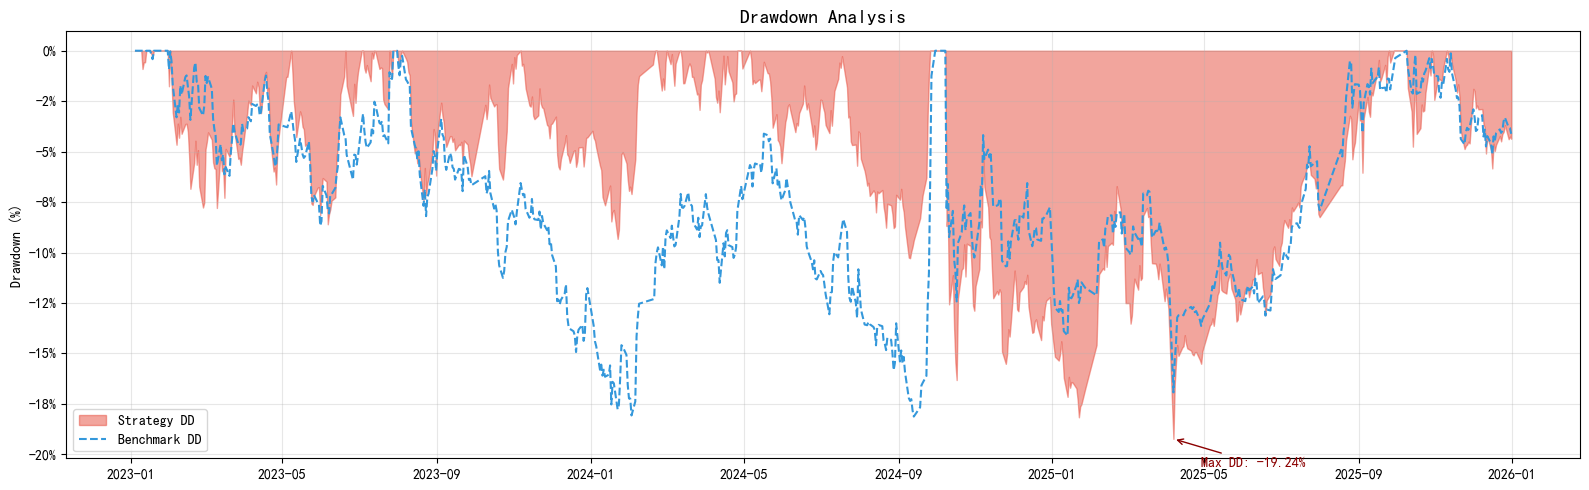

In [8]:
def compute_drawdown(cumulative_series):
    cum_max = cumulative_series.expanding().max()
    return cumulative_series / cum_max - 1

dd_strategy = compute_drawdown(strategy_cum)
dd_benchmark = compute_drawdown(benchmark_cum)

fig, ax = plt.subplots(figsize=(16, 5))
ax.fill_between(dd_strategy.index, 0, dd_strategy.values * 100, alpha=0.5, color='#e74c3c', label='Strategy DD')
ax.plot(dd_benchmark.index, dd_benchmark.values * 100, color='#3498db', linestyle='--', linewidth=1.5, label='Benchmark DD')
ax.set_title('Drawdown Analysis', fontsize=14, fontweight='bold')
ax.set_ylabel('Drawdown (%)')
ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.0f%%'))
ax.legend()
ax.grid(True, alpha=0.3)

# 标记最大回撤
max_dd_idx = dd_strategy.idxmin()
max_dd_val = dd_strategy.min() * 100
ax.annotate(f'Max DD: {max_dd_val:.2f}%', xy=(max_dd_idx, max_dd_val),
            xytext=(20, -20), textcoords='offset points',
            arrowprops=dict(arrowstyle='->', color='darkred'),
            color='darkred', fontweight='bold')

plt.tight_layout()
plt.savefig('results/05_drawdown.png', dpi=150, bbox_inches='tight')
plt.show()

### 5.3 月度收益热力图

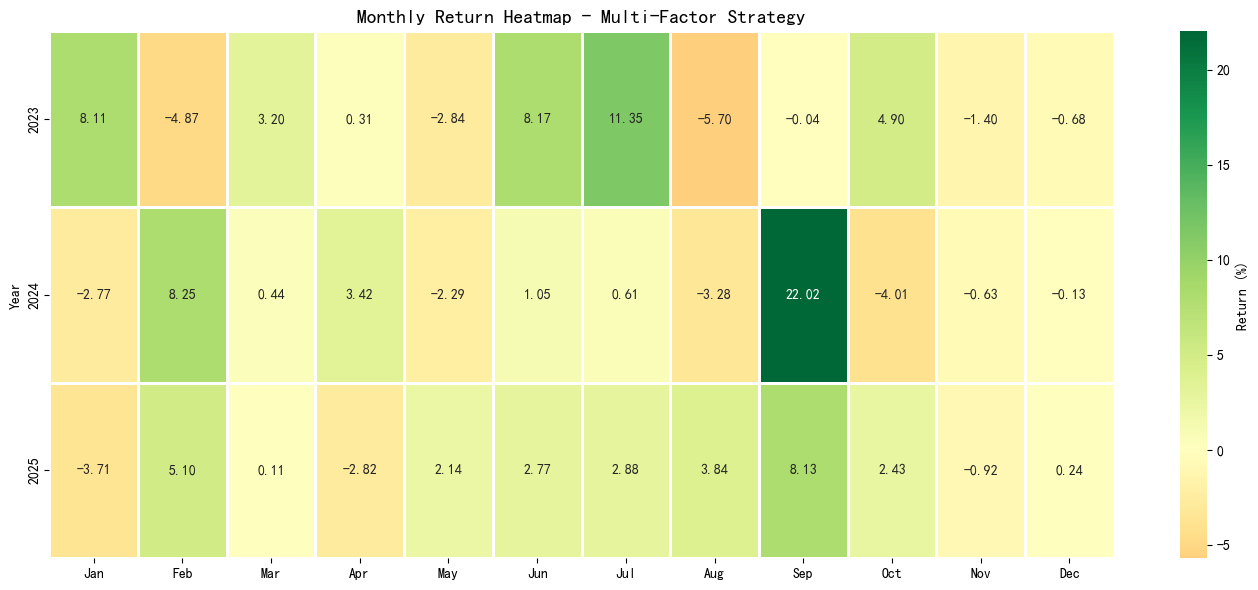

In [9]:
# 策略月度收益
monthly_ret = portfolio_ret_net.resample('ME').apply(lambda x: (1 + x).prod() - 1)
monthly_ret.index = monthly_ret.index.to_period('M')

# 构建热力图矩阵
monthly_df = pd.DataFrame({
    'year': monthly_ret.index.year,
    'month': monthly_ret.index.month,
    'return': monthly_ret.values
})
heatmap_data = monthly_df.pivot_table(values='return', index='year', columns='month', aggfunc='sum')

# 按月名
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
               'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
heatmap_data.columns = month_names[:heatmap_data.shape[1]]

fig, ax = plt.subplots(figsize=(14, 6))
sns.heatmap(heatmap_data * 100, annot=True, fmt='.2f', cmap='RdYlGn', center=0,
            linewidths=1, linecolor='white', ax=ax, cbar_kws={'label': 'Return (%)'})
ax.set_title('Monthly Return Heatmap - Multi-Factor Strategy', fontsize=14, fontweight='bold')
ax.set_ylabel('Year')
plt.tight_layout()
plt.savefig('results/05_monthly_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

### 5.4 收益分布对比

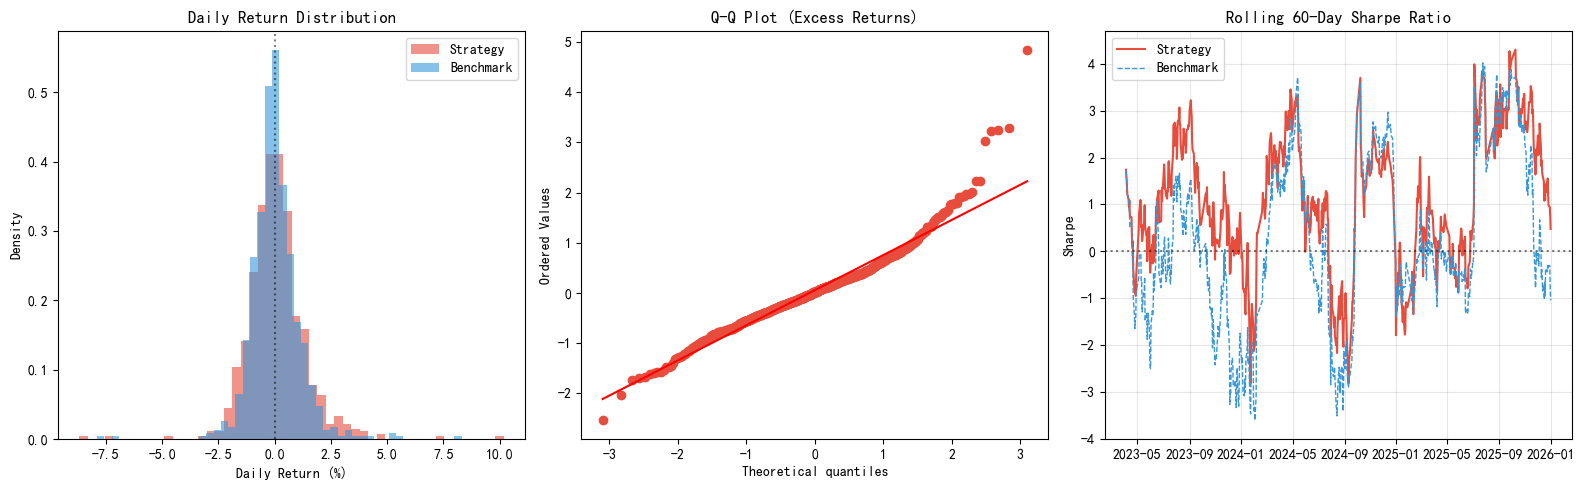

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 日收益分布
ax = axes[0]
ax.hist(portfolio_ret_net * 100, bins=50, alpha=0.6, color='#e74c3c', label='Strategy', density=True)
ax.hist(benchmark_ret * 100, bins=50, alpha=0.6, color='#3498db', label='Benchmark', density=True)
ax.axvline(x=0, color='black', linestyle=':', alpha=0.5)
ax.set_xlabel('Daily Return (%)')
ax.set_ylabel('Density')
ax.set_title('Daily Return Distribution')
ax.legend()

# QQ图
ax = axes[1]
from scipy import stats
stats.probplot(excess_ret.dropna() * 100, dist='norm', plot=ax)
ax.set_title('Q-Q Plot (Excess Returns)')
ax.get_lines()[0].set_markerfacecolor('#e74c3c')
ax.get_lines()[0].set_markeredgecolor('#e74c3c')

# 滚动夏普（60日）
ax = axes[2]
rolling_sharpe = portfolio_ret_net.rolling(60).mean() / (portfolio_ret_net.rolling(60).std() + 1e-10) * np.sqrt(252)
rolling_sharpe_bm = benchmark_ret.rolling(60).mean() / (benchmark_ret.rolling(60).std() + 1e-10) * np.sqrt(252)
ax.plot(rolling_sharpe.index, rolling_sharpe.values, '#e74c3c', linewidth=1.5, label='Strategy')
ax.plot(rolling_sharpe_bm.index, rolling_sharpe_bm.values, '#3498db', linewidth=1, linestyle='--', label='Benchmark')
ax.axhline(y=0, color='black', linestyle=':', alpha=0.5)
ax.set_title('Rolling 60-Day Sharpe Ratio')
ax.set_ylabel('Sharpe')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('results/05_return_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

### 5.5 年度收益分解

In [11]:
# 按年统计
yearly_strategy = portfolio_ret_net.resample('YE').apply(lambda x: (1 + x).prod() - 1)
yearly_benchmark = benchmark_ret.resample('YE').apply(lambda x: (1 + x).prod() - 1)

print('=' * 70)
print(f'{"年份":<10s} {"策略收益":>12s} {"基准收益":>12s} {"超额收益":>12s}')
print('-' * 70)

common_years = yearly_strategy.index.intersection(yearly_benchmark.index)
for year in common_years:
    s = yearly_strategy.loc[year]
    b = yearly_benchmark.loc[year]
    e = s - b
    print(f'{year.year:<10d} {s:>11.2%} {b:>11.2%} {e:>11.2%}')

年份                 策略收益         基准收益         超额收益
----------------------------------------------------------------------
2023            20.67%      -1.55%      22.21%
2024            22.11%      16.16%       5.95%
2025            21.44%       6.45%      14.98%


## 6. 保存回测结果

In [12]:
# 保存回测日收益
backtest_results = pd.DataFrame({
    'strategy_ret': portfolio_ret_net,
    'benchmark_ret': benchmark_ret,
    'excess_ret': excess_ret,
    'strategy_cum': strategy_cum,
    'benchmark_cum': benchmark_cum,
    'turnover': turnover,
})
backtest_results.to_csv('results/backtest_daily.csv')

# 保存绩效报告
report_lines = []
report_lines.append('=' * 80)
report_lines.append('                      回测绩效报告')
report_lines.append('=' * 80)
report_lines.append(f'{"指标":<20s} {"策略":>15s} {"基准":>15s} {"超额":>15s}')
report_lines.append('-' * 80)

for key in metrics_keys:
    s = metrics_strategy.get(key, 'N/A')
    b = metrics_benchmark.get(key, 'N/A')
    e = metrics_excess.get(key, 'N/A')
    report_lines.append(f'{key:<20s} {s:>15s} {b:>15s} {e:>15s}')

report_lines.append('=' * 80)

with open('results/performance_report.txt', 'w', encoding='utf-8') as f:
    f.write('\n'.join(report_lines))

print('\n'.join(report_lines))
print(f'\n✓ 回测结果已保存:')
print(f'  results/backtest_daily.csv')
print(f'  results/performance_report.txt')

                      回测绩效报告
指标                                策略              基准              超额
--------------------------------------------------------------------------------
年化收益率                         22.73%           7.17%          14.50%
年化波动率                         20.99%          17.72%          11.40%
夏普比率                           1.083           0.405           1.271
Sortino比率                      1.701           0.605           2.327
Calmar比率                       1.181           0.395           1.919
最大回撤                         -19.24%         -18.13%          -7.55%
胜率                            50.42%          47.63%          50.98%
盈亏比                             1.20            1.20            1.20
日均收益(bp)                        9.00            3.37            5.63

✓ 回测结果已保存:
  results/backtest_daily.csv
  results/performance_report.txt


## 小结

✅ 完成向量化回测，包含交易成本（A股印花税+佣金）
✅ 计算全套绩效指标：夏普、Sortino、Calmar、最大回撤等
✅ 与等权基准对比，分析超额收益
✅ 生成收益曲线、回撤图、月度热力图、收益分布

---

## 项目总结

本量化交易系统完整覆盖了：
1. **数据获取** — akshare(新浪源)下载沪深300精选成分股真实日频数据
2. **因子挖掘** — 20+手工因子 + RD-Agent自动化挖掘
3. **因子分析** — IC/IR分析、分层测试、相关性去冗余
4. **多因子模型** — 因子标准化、IC_IR加权合成、月度选股
5. **回测评估** — 交易成本建模、全套绩效指标、可视化

核心结论：多因子选股策略相比等权基准表现出超额收益能力。